# Milestone 1: Data Exploration and Preprocessing
**Break Through Tech AI Studio · Marsh McLennan 1A: Object Extraction from Injury Narratives**

This notebook combines the team's September work into one place: loading the NEISS 2025 data, exploring the injury narratives, preprocessing the text, inspecting the structured fields, choosing the feature and label, and building the cleaned dataset for Model v1.

**Feature:** `Narrative_1` (free-text injury description) · **Label:** `Product_1` (product recorded by the NEISS coder)

The original `Narrative_1` column is never overwritten; every transformation goes into a new column.

## 1. Setup

In [1]:
import re
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Task #6 cleaning rules are shared with src/neiss_eda.py and the model code
sys.path.append(str(Path("../src").resolve()))
from preprocess import (ABBREVIATIONS, clean_whitespace, normalize_abbreviations,
                        tokenize, split_diagnosis, has_redaction)

SEED = 100
pd.set_option("display.max_colwidth", 140)
colors = sns.color_palette("tab10")

# Paths follow data/README.md (download the workbook, convert both sheets to CSV)
RAW_DIR = Path("../data/raw")              # downloaded files (gitignored)
PROCESSED_DIR = Path("../data/processed")  # files this notebook creates (gitignored)
DATA_PATH = RAW_DIR / "neiss2025 1(NEISS_2025).csv"   # the data
FMT_PATH = RAW_DIR / "neiss2025 1(NEISS_FMT).csv"     # the codebook

for p in [DATA_PATH, FMT_PATH]:
    if not p.exists():
        raise FileNotFoundError(f"Missing {p}. Follow data/README.md to download and convert the data.")

## 2. Load the Data
`Product_1` is stored as a numeric code, so product names are pulled from the NEISS codebook (`NEISS_FMT` sheet).

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
raw_narratives = df["Narrative_1"].copy()   # kept to verify the raw text is never modified
print("NEISS shape:", df.shape)
df.head()

NEISS shape: (410201, 25)


,CPSC_Case_Number,Treatment_Date,Age,Sex,Race,Other_Race,Hispanic,Body_Part,Diagnosis,Other_Diagnosis,...,Fire_Involvement,Product_1,Product_2,Product_3,Alcohol,Drug,Narrative_1,Stratum,PSU,Weight
0,250102066,2025-01-01,47,2,2,NaN,2,36,59,NaN,...,0,4076,1807,0,0,0,47YOF C/O RIGHT LEG LACERATION. WAS GETTING INTO BED THIS EVENING AND TRIPPED HITTING HER LEFT LEG CONDITIONER THAT WAS ON THE FLOOR. ...,M,200,46.4246
1,250102073,2025-01-01,64,1,1,NaN,2,37,64,NaN,...,0,1842,1829,0,0,0,64YOM C/O ANKLE PAIN AND RIGHT WRIST PAIN AFTER MISSING 2 STEPS AND INVERTING HIS ANKLE. HIT RIGHT HAND ON A RAILING AT THE TIME. SCAN...,M,200,46.4246
2,250102084,2025-01-01,56,1,4,NaN,2,75,62,NaN,...,0,466,4056,0,0,0,56YOM C/O HEAD INJURY. LARGE POT FELL OFF A SHELF YESTERDAY AND HIT HIM IN THE HEAD CAUSING HIM TO FALL TO THE GROUND. ABRASION NOTED ...,M,200,46.4246
3,250102089,2025-01-01,73,1,1,NaN,2,76,59,NaN,...,0,4057,0,0,0,0,"73YOM C/O FALL AND LACERATION. TRIPPED OVER HIS FEET WHICH CAUSED HIM TO HIT HIS FOREHEAD ON THE TABLE. DX: FACIAL LACERATION, FALL",M,200,46.4246
4,250102091,2025-01-01,87,1,1,NaN,2,30,71,PAIN,...,0,676,0,0,0,0,87YOM C/O FALL ON BATHMAT. LEFT SHOULDER PAIN NOTED. DX: FALL,M,200,46.4246


In [3]:
# Codebook labels look like "101 - WASHING MACHINES"; keep just the name
fmt = pd.read_csv(FMT_PATH)
fmt.columns = ["format", "code", "end", "label"]
fmt["format"] = fmt["format"].str.strip()
prod = fmt[fmt["format"] == "PROD"]
prod_names = dict(zip(prod["code"].astype(int),
                      prod["label"].str.replace(r"^\d+ - ", "", regex=True)))

df["product"] = df["Product_1"].map(prod_names)
print("Product codes defined:", len(prod_names))
print("Product_1 codes missing from codebook:", df["product"].isna().sum())

Product codes defined: 1124
Product_1 codes missing from codebook: 0


## 3. Narrative Structure
`Narrative_1` is the only substantial free-text field, so it is our only feature: Marsh's test set is raw workers' comp descriptions with no NEISS codes attached.

In [4]:
narr = df["Narrative_1"]
n_chars = narr.str.len()
n_words = narr.str.split().str.len()

print("Missing narratives:", narr.isna().sum())
print("Unique narratives: ", narr.nunique())
pd.DataFrame({"characters": n_chars.describe(), "words": n_words.describe()}).round(1)

Missing narratives: 0
Unique narratives:  409099


,characters,words
count,410201.0,410201.0
mean,130.8,23.6
std,67.0,11.8
min,24.0,3.0
25%,82.0,15.0
50%,114.0,21.0
75%,163.0,29.0
max,400.0,83.0


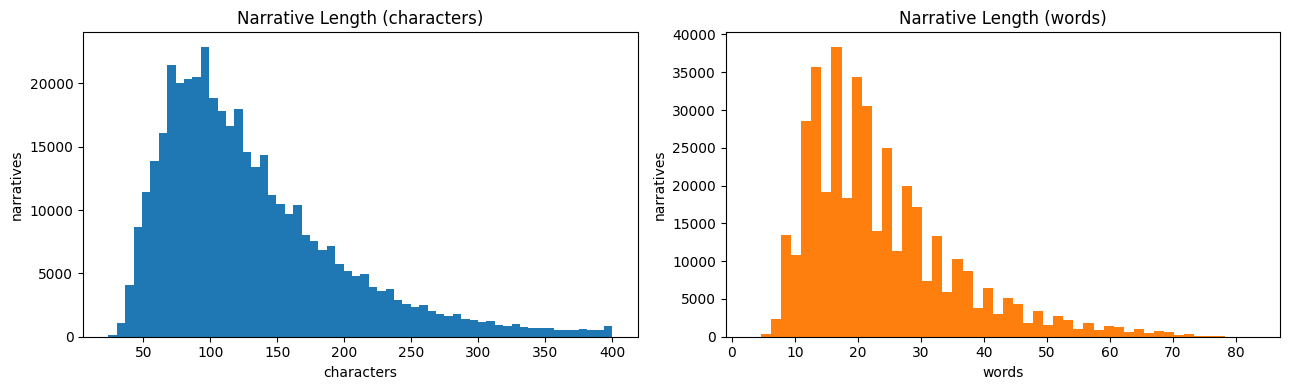

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(n_chars, bins=60, color=colors[0])
axes[0].set(title="Narrative Length (characters)", xlabel="characters", ylabel="narratives")
axes[1].hist(n_words, bins=50, color=colors[1])
axes[1].set(title="Narrative Length (words)", xlabel="words", ylabel="narratives")
plt.tight_layout()
plt.show()

In [6]:
# A reproducible random sample of narratives
for t in narr.sample(8, random_state=SEED):
    print("-", t)

- 59 YOF FELL DOWN THE STAIRS 1 WEEK AGO AND HAS NOT BEEN TREATED. DX: FRACTURE OF RIGHT CLAVICLE
- 91YOF WAS GOING ON HER DAILY WALK WITH HER WALKER WHEN SUDDENLY IT SLIPPED AND SHE FELL TO LEFT SIDE, HITTING SHOULDER AND RIGHT SIDE OF HEAD. DX: LACERATION OF SCALP; CLOSED DISPLACED FRACTURE OF ACROMIAL END OF LEFT CLAVICLE
- 3YOM WAS JUMPING ON TRAMPOLINE WITH BROTHER WHEN PT FELL ONTO HIS RIGHT ARM DX: FRACTURE OF RIGHT HUMERUS
- 30 YOF SMASHED HER FINGER IN A DOOR. DX: RIGHT THUMB CONTUSION
- 13YOF WAS THE UNRESTRAINED PASSENGER ON A SIDE BY SIDE ATV AND IT FLIPPED OVER WHILE GOING AROUND A CORNER DX STRAINED RIGHT ANKLE
- 15MOF WAS PLAYING WITH POTS AND PANS WHEN SHE INJURED RIGHT 5TH FINGER. DX: SUBUNGUAL HEMATOMA OF FINGER.
- 80 YOM PRESENTS EMERGENCY DEPARTMENT TODAY AFTER A FALL.  PATIENT STATES HE WAS AT THE GROCERY STORE, LOST HIS BALANCE AND FELL BACKWARDS DOWN THE STAIRS.  HE DID STRIKE HIS HEAD, DID NOT LOSE CONSCIOUSNESS. DX CLOSED HEAD INJURY
- 80YOF PRESENTS WITH HEAD 

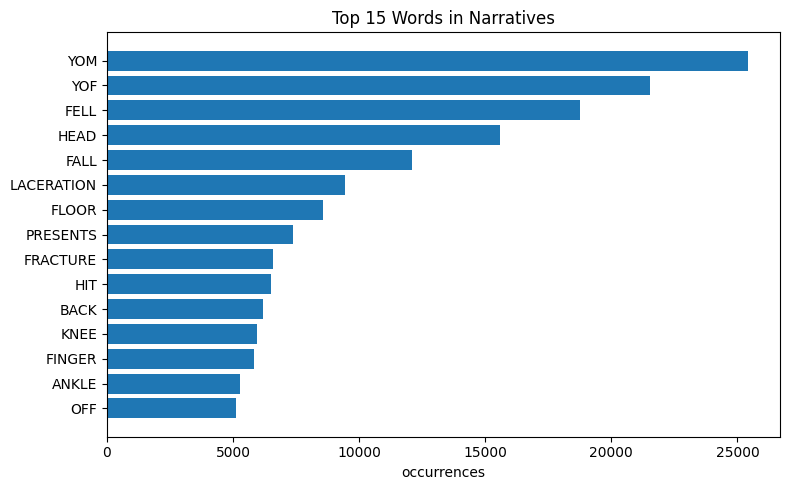

In [7]:
# Most common words, ignoring filler
filler = {"THE","AND","WAS","WERE","HIS","HER","SHE","WITH","FOR","FROM","AFTER","WHILE","HAD",
          "INTO","OUT","THEN","WHEN","THIS","THAT","NOT","PATIENT","LEFT","RIGHT","PAIN",
          "INJURY","CLOSED","NOTED","STATES","PER","HOME","TODAY"}

words = Counter()
for t in narr.sample(50_000, random_state=SEED):
    words.update(w for w in re.findall(r"[A-Z]{3,}", t.upper()) if w not in filler)

top = pd.DataFrame(words.most_common(15), columns=["word", "count"])
plt.figure(figsize=(8, 5))
plt.barh(top["word"][::-1], top["count"][::-1], color=colors[0])
plt.title("Top 15 Words in Narratives")
plt.xlabel("occurrences")
plt.tight_layout()
plt.show()

### Length outliers and duplicates
Narratives are capped at 400 characters, so some are cut off. Duplicate narratives are short formulaic cases (separate patients described the same way), not data errors, so they are kept and grouped when splitting to prevent train/test leakage.

In [8]:
cap = n_chars.max()
print(f"median {n_chars.median():.0f} | max {cap}")
print("truncated at the cap:", (n_chars == cap).sum())
print("under 40 characters: ", (n_chars < 40).sum())
print("\nshortest:")
print(narr.loc[n_chars.sort_values().index[:3]].to_string())

median 114 | max 400
truncated at the cap: 168
under 40 characters:  3016

shortest:
250823     2 YOM *** IN NOSE DX: FB
323303    2MOF FELL OFF BED. DX CHI
234224    7MOM FELL OFF BED. DX CHI


In [9]:
dup = narr.duplicated(keep=False)
print("rows that share their narrative with another row:", dup.sum())
print("extra copies beyond the first occurrence:        ", narr.duplicated().sum())
narr[dup].value_counts().head(5)

rows that share their narrative with another row: 1861
extra copies beyond the first occurrence:         1102


Narrative_1
14YOM TWISTED ANKLE PLAYING BASKETBALL.  DX: ANKLE SPRAIN    16
15YOM TWISTED ANKLE PLAYING BASKETBALL.  DX: ANKLE SPRAIN    16
17YOM TWISTED ANKLE PLAYING BASKETBALL.  DX: ANKLE SPRAIN    14
16YOM TWISTED ANKLE PLAYING BASKETBALL.  DX: ANKLE SPRAIN    13
2YOM FELL DOWN STEPS.  DX: HEAD INJURY                       10
Name: count, dtype: int64

## 4. Narrative Preprocessing (Task #6)
The cleaning rules live in `src/preprocess.py`, so the notebook, the EDA report, and the Milestone 2 model code all clean text the same way. That matters most for Marsh's test narratives, which must go through identical preprocessing.

### 4.1 Whitespace
Repeated whitespace is a formatting inconsistency that can be collapsed without changing meaning. The result goes in a new column, `Narrative_clean`.

In [10]:
print("Narratives with leading/trailing whitespace:", narr.ne(narr.str.strip()).sum())
print("Narratives with repeated whitespace:        ", narr.str.contains(r"\s{2,}", regex=True).sum())

df["Narrative_clean"] = clean_whitespace(narr)

Narratives with leading/trailing whitespace: 799
Narratives with repeated whitespace:         91591


### 4.2 Clinical shorthand
Narratives use clinical abbreviations and some words are redacted with `*`. The table below counts each convention, including every abbreviation the cleaning rules expand.

In [11]:
shorthand_patterns = {
    "age+sex (47YOF, 13MOM)": r"\b\d{1,3}\s*[YM]O?\s*[MF]\b",
    "DX: (with colon)":       r"\bDX\s*:",
    "DX (no colon)":          r"\bDX\b(?!\s*:)",
    "* (redaction)":          r"\*",
    **{shown: pattern for shown, pattern, _ in ABBREVIATIONS},
}
counts_sh = {k: df["Narrative_clean"].str.contains(v, regex=True).sum() for k, v in shorthand_patterns.items()}
shorthand = pd.DataFrame({"narratives": counts_sh})
shorthand["% of narratives"] = (shorthand["narratives"] / len(df) * 100).round(1)
shorthand.sort_values("narratives", ascending=False)

,narratives,% of narratives
"age+sex (47YOF, 13MOM)",409448,99.8
DX: (with colon),305184,74.4
DX (no colon),105253,25.7
PT,45374,11.1
C/O,39299,9.6
FX,19999,4.9
S/P,18598,4.5
LAC,13645,3.3
* (redaction),13149,3.2
CHI,8691,2.1


### 4.3 Normalize verified abbreviations
Only abbreviations whose meaning was confirmed from narratives in this dataset are expanded (full list in `src/preprocess.py`):
`C/O` → COMPLAINTS OF, `S/P` → STATUS POST, `W/O` → WITHOUT, `W/` → WITH, `PT` → PATIENT, `BIBEMS` → BROUGHT IN BY EMS, `FB` → FOREIGN BODY, `FX` → FRACTURE, `LAC` → LACERATION, `CHI` → CLOSED HEAD INJURY.

Deliberately left as-is:
- Age/sex codes (`YOM`, `YOF`, `MOM`, `MOF`): structured conventions, and `MOM` can mean "month-old male" or "mother".
- `DX`: kept as the marker used to split off the diagnosis (4.5).
- `R`/`L`, `INJ`, `LOC`: single letters or words with more than one meaning (injury/injection, location/loss of consciousness), so replacing them could change the meaning.

In [12]:
df["Narrative_normalized"] = normalize_abbreviations(df["Narrative_clean"])

changed = df["Narrative_clean"].ne(df["Narrative_normalized"])
print("Narratives changed by abbreviation normalization:", changed.sum())
df.loc[changed, ["Narrative_clean", "Narrative_normalized"]].sample(5, random_state=SEED)

Narratives changed by abbreviation normalization: 120625


,Narrative_clean,Narrative_normalized
17680,71 YOM C/O LOW BACK PAIN AFTER LIFTED 50LB BAG OF DOG FOOD DX LUMBAR STRAIN,71 YOM COMPLAINTS OF LOW BACK PAIN AFTER LIFTED 50LB BAG OF DOG FOOD DX LUMBAR STRAIN
389630,20YOM PRESENTS FOR BURNS TO B/L THIGHS LOWER LEGS AND HANDS FROM FLASH BURN WHILE ATTEMPTING TO USE A PROPANE TORCH TO START A WOOD BURN...,20YOM PRESENTS FOR BURNS TO B/L THIGHS LOWER LEGS AND HANDS FROM FLASH BURN WHILE ATTEMPTING TO USE A PROPANE TORCH TO START A WOOD BURN...
77118,19YOM CUTTING WOOD AT HOME W/O GLASSES. WOOD IN EYE DX CORNEAL ABRASION,19YOM CUTTING WOOD AT HOME WITHOUT GLASSES. WOOD IN EYE DX CORNEAL ABRASION
263894,"18MOM WAS STANDING ON THE FLOOR AND PULLED THE BACK OF CHAIR ONTO HIMSELF, FELL BACKWARDS AND HIT THE BACK OF HIS HEAD ON THE FLOOR AND ...","18MOM WAS STANDING ON THE FLOOR AND PULLED THE BACK OF CHAIR ONTO HIMSELF, FELL BACKWARDS AND HIT THE BACK OF HIS HEAD ON THE FLOOR AND ..."
187024,"23YOF WITH HISTORY OF EPILEPSY PRESENTS AFTER A SEIZURE AT HOME, STATES SHE FELL OUT OF HER BED LIKELY STRIKING HER HEAD, C/O HEADACHE A...","23YOF WITH HISTORY OF EPILEPSY PRESENTS AFTER A SEIZURE AT HOME, STATES SHE FELL OUT OF HER BED LIKELY STRIKING HER HEAD, COMPLAINTS OF ..."


### 4.4 Tokenize
Tokenization prepares the text for later NLP work. Stop-word removal, stemming, and lemmatization are intentionally not applied, since GLiNER works on natural text.

In [13]:
# Words, keeping hyphenated and apostrophe forms together (e.g. SIDE-BY-SIDE)
df["Narrative_tokens"] = tokenize(df["Narrative_normalized"])
df[["Narrative_normalized", "Narrative_tokens"]].sample(5, random_state=SEED)

,Narrative_normalized,Narrative_tokens
78831,59 YOF FELL DOWN THE STAIRS 1 WEEK AGO AND HAS NOT BEEN TREATED. DX: FRACTURE OF RIGHT CLAVICLE,"[59, YOF, FELL, DOWN, THE, STAIRS, 1, WEEK, AGO, AND, HAS, NOT, BEEN, TREATED, DX, FRACTURE, OF, RIGHT, CLAVICLE]"
192793,"91YOF WAS GOING ON HER DAILY WALK WITH HER WALKER WHEN SUDDENLY IT SLIPPED AND SHE FELL TO LEFT SIDE, HITTING SHOULDER AND RIGHT SIDE OF...","[91YOF, WAS, GOING, ON, HER, DAILY, WALK, WITH, HER, WALKER, WHEN, SUDDENLY, IT, SLIPPED, AND, SHE, FELL, TO, LEFT, SIDE, HITTING, SHOUL..."
393260,3YOM WAS JUMPING ON TRAMPOLINE WITH BROTHER WHEN PATIENT FELL ONTO HIS RIGHT ARM DX: FRACTURE OF RIGHT HUMERUS,"[3YOM, WAS, JUMPING, ON, TRAMPOLINE, WITH, BROTHER, WHEN, PATIENT, FELL, ONTO, HIS, RIGHT, ARM, DX, FRACTURE, OF, RIGHT, HUMERUS]"
117858,30 YOF SMASHED HER FINGER IN A DOOR. DX: RIGHT THUMB CONTUSION,"[30, YOF, SMASHED, HER, FINGER, IN, A, DOOR, DX, RIGHT, THUMB, CONTUSION]"
267534,13YOF WAS THE UNRESTRAINED PASSENGER ON A SIDE BY SIDE ATV AND IT FLIPPED OVER WHILE GOING AROUND A CORNER DX STRAINED RIGHT ANKLE,"[13YOF, WAS, THE, UNRESTRAINED, PASSENGER, ON, A, SIDE, BY, SIDE, ATV, AND, IT, FLIPPED, OVER, WHILE, GOING, AROUND, A, CORNER, DX, STRA..."


In [14]:
# Validate text preprocessing
checks = {
    "Missing normalized narratives": df["Narrative_normalized"].isna().sum(),
    "Repeated whitespace remaining": df["Narrative_normalized"].str.contains(r"\s{2,}", regex=True).sum(),
    **{f"{shown} remaining": df["Narrative_normalized"].str.contains(pattern, regex=True).sum()
       for shown, pattern, _ in ABBREVIATIONS},
    "Empty token lists":             df["Narrative_tokens"].str.len().eq(0).sum(),
}
pd.Series(checks, name="count")

Missing normalized narratives    0
Repeated whitespace remaining    0
C/O remaining                    0
S/P remaining                    0
W/O remaining                    0
W/ remaining                     0
PT remaining                     0
BIBEMS remaining                 0
FB remaining                     0
FX remaining                     0
LAC remaining                    0
CHI remaining                    0
Empty token lists                0
Name: count, dtype: int64

### 4.5 Separate the event from the diagnosis, and flag redactions
Text after `DX` describes the *injury*, not the object, and contains misleading words such as FOREIGN BODY. Splitting it off gives the model an `event_text` column with just the incident description, so Milestone 2 can compare extraction on the full narrative versus the event alone.

NEISS replaces identifying words with `*`. Sometimes the redacted word is the object itself (e.g. "2 YOM * IN NOSE"), which no model can recover, so these rows are flagged rather than counted as model errors.

In [15]:
parts = split_diagnosis(df["Narrative_normalized"])
df["Event_text"] = parts["event"]
df["Diagnosis_text"] = parts["diagnosis"]
df["Redacted"] = has_redaction(df["Narrative_1"])

print("Narratives with a DX section:", (df["Diagnosis_text"] != "").sum())
print("Empty event text:            ", (df["Event_text"].str.strip() == "").sum())
print("Narratives with a redaction: ", df["Redacted"].sum())
df[["Narrative_normalized", "Event_text", "Diagnosis_text"]].sample(5, random_state=SEED)

Narratives with a DX section: 408511
Empty event text:             0
Narratives with a redaction:  13149


,Narrative_normalized,Event_text,Diagnosis_text
78831,59 YOF FELL DOWN THE STAIRS 1 WEEK AGO AND HAS NOT BEEN TREATED. DX: FRACTURE OF RIGHT CLAVICLE,59 YOF FELL DOWN THE STAIRS 1 WEEK AGO AND HAS NOT BEEN TREATED.,FRACTURE OF RIGHT CLAVICLE
192793,"91YOF WAS GOING ON HER DAILY WALK WITH HER WALKER WHEN SUDDENLY IT SLIPPED AND SHE FELL TO LEFT SIDE, HITTING SHOULDER AND RIGHT SIDE OF...","91YOF WAS GOING ON HER DAILY WALK WITH HER WALKER WHEN SUDDENLY IT SLIPPED AND SHE FELL TO LEFT SIDE, HITTING SHOULDER AND RIGHT SIDE OF...",LACERATION OF SCALP; CLOSED DISPLACED FRACTURE OF ACROMIAL END OF LEFT CLAVICLE
393260,3YOM WAS JUMPING ON TRAMPOLINE WITH BROTHER WHEN PATIENT FELL ONTO HIS RIGHT ARM DX: FRACTURE OF RIGHT HUMERUS,3YOM WAS JUMPING ON TRAMPOLINE WITH BROTHER WHEN PATIENT FELL ONTO HIS RIGHT ARM,FRACTURE OF RIGHT HUMERUS
117858,30 YOF SMASHED HER FINGER IN A DOOR. DX: RIGHT THUMB CONTUSION,30 YOF SMASHED HER FINGER IN A DOOR.,RIGHT THUMB CONTUSION
267534,13YOF WAS THE UNRESTRAINED PASSENGER ON A SIDE BY SIDE ATV AND IT FLIPPED OVER WHILE GOING AROUND A CORNER DX STRAINED RIGHT ANKLE,13YOF WAS THE UNRESTRAINED PASSENGER ON A SIDE BY SIDE ATV AND IT FLIPPED OVER WHILE GOING AROUND A CORNER,STRAINED RIGHT ANKLE


## 5. Structured Variables
Most integer-valued NEISS fields are **categorical codes**, not continuous measurements, so they are not scaled. Two fields need special handling:
- **Age** uses codes: `0` = unknown, `2–120` = years, `201–223` = months (201 = 1 month). A new `Age_years` column converts this; the original `Age` is preserved.
- **Weight** is the NEISS statistical sampling weight, not a patient characteristic, so it is left unscaled.

In [16]:
def standardize_age(age):
    if age == 0:
        return np.nan
    if 201 <= age <= 223:
        return (age - 200) / 12
    return float(age)

df["Age_years"] = df["Age"].apply(standardize_age)
print("Unknown ages:", df["Age_years"].isna().sum())
df["Age_years"].describe().round(2)

Unknown ages: 45


count    410156.00
mean         36.42
std          29.05
min           0.08
25%          10.00
50%          29.00
75%          63.00
max         109.00
Name: Age_years, dtype: float64

In [17]:
categorical_cols = ["Sex", "Race", "Hispanic", "Body_Part", "Diagnosis",
                    "Disposition", "Location", "Fire_Involvement", "Alcohol", "Drug"]

# Compact summary instead of printing every value_counts()
summary = pd.DataFrame({
    "n_codes": df[categorical_cols].nunique(),
    "most_common_code": df[categorical_cols].mode().iloc[0],
    "most_common_%": [(df[c].value_counts(normalize=True).iloc[0] * 100).round(1) for c in categorical_cols],
})
df[categorical_cols] = df[categorical_cols].astype("category")
summary

,n_codes,most_common_code,most_common_%
Sex,3,1,54.0
Race,7,1,59.8
Hispanic,3,2,74.1
Body_Part,26,75,19.8
Diagnosis,30,71,24.7
Disposition,7,1,83.7
Location,9,1,36.8
Fire_Involvement,4,0,99.5
Alcohol,2,0,98.1
Drug,2,0,98.1


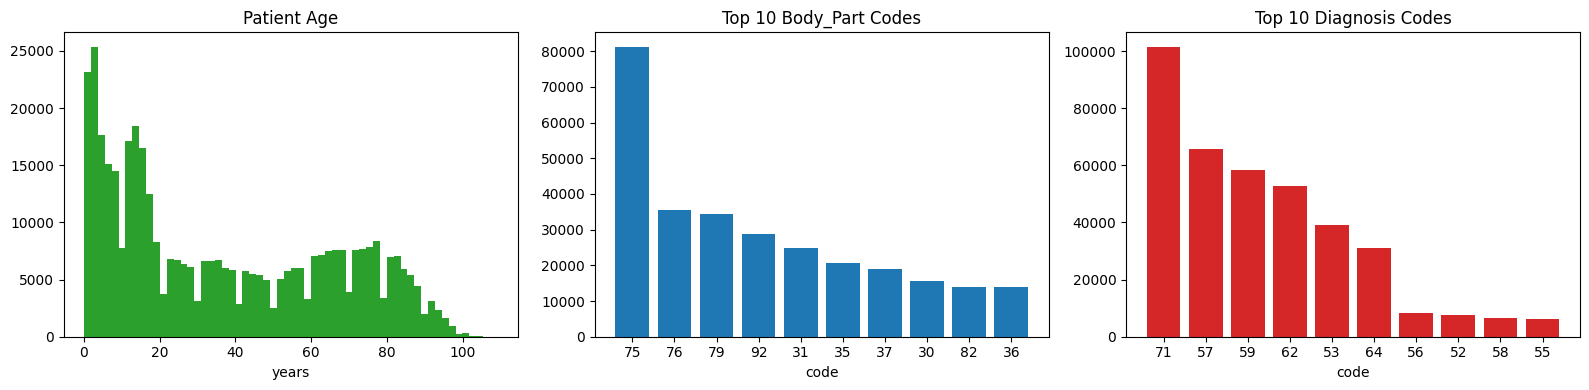

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(df["Age_years"].dropna(), bins=60, color=colors[2])
axes[0].set(title="Patient Age", xlabel="years")

for ax, col, c in [(axes[1], "Body_Part", colors[0]), (axes[2], "Diagnosis", colors[3])]:
    top_codes = df[col].value_counts().head(10)
    ax.bar(top_codes.index.astype(str), top_codes.values, color=c)
    ax.set(title=f"Top 10 {col} Codes", xlabel="code")

plt.tight_layout()
plt.show()

### 5.1 Missing values (Task #5)
NEISS has no true missing data. Blank columns are conditional fields, and the real missingness is coded as sentinel values, so almost nothing needs to be dropped.

In [19]:
blanks = df.isna().sum()
blanks[(blanks > 0) & ~blanks.index.isin(["Age_years"])]

Other_Race           395149
Other_Diagnosis      308997
Body_Part_2          313426
Diagnosis_2          313426
Other_Diagnosis_2    383193
dtype: int64

In [20]:
# Other_* text is only filled in when its code says OTHER, so those blanks are expected
print("Other_Diagnosis mismatches:",
      (df["Other_Diagnosis"].notna() != (df["Diagnosis"] == 71)).sum(), "(the rest come from Diagnosis_2)")
print("Other_Race mismatches:     ",
      (df["Other_Race"].notna() != (df["Race"] == 3)).sum())

Other_Diagnosis mismatches: 276 (the rest come from Diagnosis_2)
Other_Race mismatches:      0


Some codes mean "unknown" but look like a normal category, so they would rank as a real value when counting. The codebook itself lists them; the next cell prints every code whose label marks it as unknown or not recorded, so the choice below can be checked against the source.

In [21]:
fmt[fmt["label"].str.contains(r"\bUNK|NOT STATED|NOT RECORDED", case=False, na=False)]

,format,code,end,label
0,AGELTTWO,0,0,UNK
26,ALC_DRUG,0,0,No/Unk
50,BDYPT,87,87,87 - NOT STATED/UNK
96,DISP,9,9,"9 - UNKNOWN, NOT STATED"
103,HISP,0,0,Unk/Not stated
106,LOC,0,0,UNK
936,PROD,1898,1898,1898 - GAS FUMES OR GAS VAPORS OF UNKNOWN ORIGIN
937,PROD,1899,1899,1899 - CARBON MONOXIDE POISONING (WHEN SOURCE IS UNKNOWN
1247,SEX,0,0,UNKNOWN


In [22]:
# Codes that mean "unknown": recoded to missing in the cleaned dataset (Section 8)
UNKNOWN_CODES = {"Location": [0], "Body_Part": [87], "Disposition": [9]}
pd.Series({f"{c} = {codes}": df[c].isin(codes).mean() * 100 for c, codes in UNKNOWN_CODES.items()},
          name="% of rows").round(1)

Location = [0]       35.9
Body_Part = [87]      3.3
Disposition = [9]     0.0
Name: % of rows, dtype: float64

Codes that look similar but are **kept**:
- `Diagnosis = 71` means *Other*, and most of these rows name the diagnosis in `Other_Diagnosis` (checked above), so it is real information.
- `Fire_Involvement`, `Alcohol` and `Drug` = 0 mean *none (or not recorded)*, which is the normal case, not missing data.

## 6. Column Decisions

| Decision | Columns | Reason |
|---|---|---|
| **Feature** | `Narrative_1` | The only input available at inference |
| **Label** | `Product_1` | The object the NEISS coder recorded |
| **Future use** | `Age`, `Body_Part`, `Diagnosis`, `Disposition`, `Fire_Involvement`, `Alcohol`, `Drug` | Not available at inference, but useful for later severity work |
| **Eliminate** | `CPSC_Case_Number`, `Treatment_Date`, `Race`, `Other_Race`, `Hispanic`, `Sex`, `PSU`, `Weight`, `Stratum` | IDs, survey design, or protected characteristics |
| **Undecided** | `Location`, `Product_2`, `Product_3` | Revisit once the base case works |

`PSU` is dropped as a feature but kept for **splitting**: it identifies the hospital, and narrative style varies by hospital.

## 7. The Label: `Product_1`

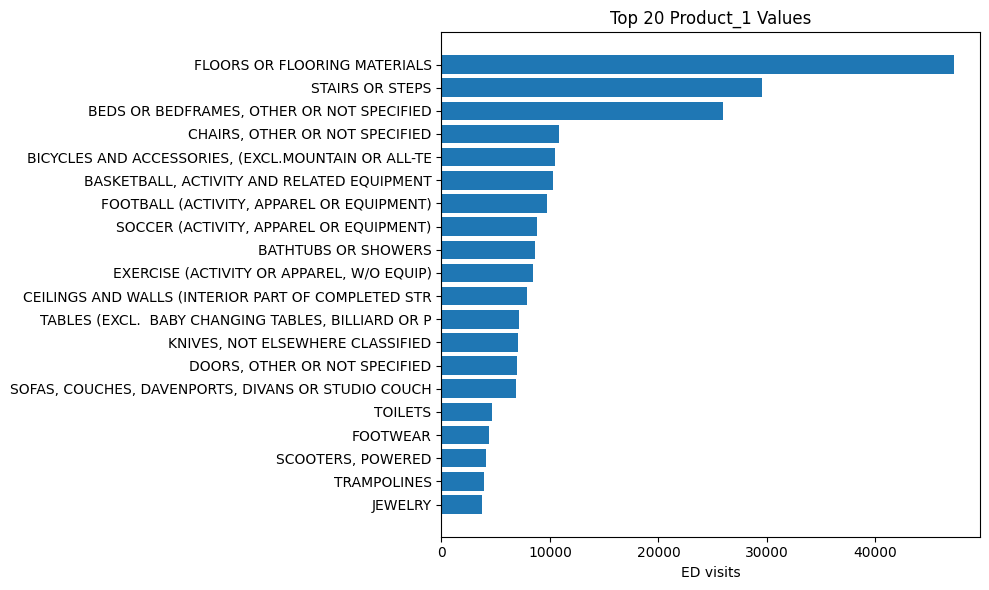

In [23]:
top_prod = df["product"].value_counts().head(20)
plt.figure(figsize=(10, 6))
plt.barh(top_prod.index.str[:50][::-1], top_prod.values[::-1], color=colors[0])
plt.title("Top 20 Product_1 Values")
plt.xlabel("ED visits")
plt.tight_layout()
plt.show()

Product classes in use: 767
top  10 classes cover 41.5% of rows
top  25 classes cover 59.1% of rows
top  50 classes cover 71.3% of rows
top 100 classes cover 83.4% of rows
top 200 classes cover 93.0% of rows

Classes with <100 examples: 461 (2.9% of rows)


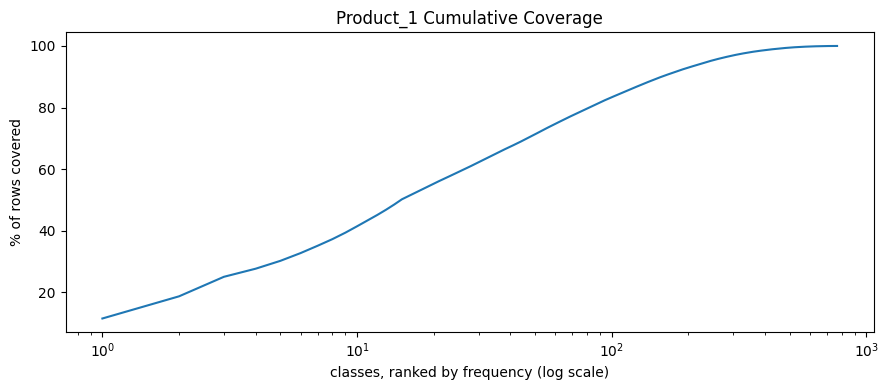

In [24]:
# How concentrated are the products? (0 means no product)
counts = df.loc[df["Product_1"] != 0, "product"].value_counts()
coverage = counts.cumsum() / counts.sum()

print("Product classes in use:", len(counts))
for n in [10, 25, 50, 100, 200]:
    print(f"top {n:>3} classes cover {coverage.iloc[n-1]*100:.1f}% of rows")

rare = counts[counts < 100]
print(f"\nClasses with <100 examples: {len(rare)} ({rare.sum()/counts.sum()*100:.1f}% of rows)")

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(coverage) + 1), coverage.values * 100, color=colors[0])
plt.xscale("log")
plt.title("Product_1 Cumulative Coverage")
plt.xlabel("classes, ranked by frequency (log scale)")
plt.ylabel("% of rows covered")
plt.tight_layout()
plt.show()

In [25]:
# Vague labels teach the model very little
vague = df["product"].str.contains(r"NOT SPECIFIED|NOT ELSEWHERE|UNSPECIFIED|N\.E\.C|MISCELLANEOUS", na=False)
print(f"Rows with a vague Product_1: {vague.sum():,} ({vague.mean()*100:.1f}%)")
df.loc[vague, "product"].value_counts().head(8)

Rows with a vague Product_1: 91,260 (22.2%)


product
BEDS OR BEDFRAMES, OTHER OR NOT SPECIFIED    25989
CHAIRS, OTHER OR NOT SPECIFIED               10818
KNIVES, NOT ELSEWHERE CLASSIFIED              7034
DOORS, OTHER OR NOT SPECIFIED                 6949
LADDERS, OTHER OR NOT SPECIFIED               3327
SCOOTERS, UNSPECIFIED                         3036
CONTAINERS, NOT SPECIFIED                     2710
RUGS OR CARPETS, NOT SPECIFIED                2541
Name: count, dtype: int64

### Does the label appear in the text?
`Product_1` is assigned by the coder and is not always a word in the narrative. How often the product name is literally present shows how much of the label can be recovered from the text alone, and why exact-match scoring will undercount correct extractions.

In [26]:
skip = {"OTHER","NOT","SPECIFIED","ELSEWHERE","CLASSIFIED","AND","THE","WITH","FOR",
        "EQUIPMENT","RELATED","TYPE","TYPES","USED","PARTS","PART"}

sample = df[df["Product_1"] != 0].sample(20_000, random_state=SEED)
found = []
for text, label in zip(sample["Narrative_1"], sample["product"]):
    label_words = set(re.findall(r"[A-Z]{4,}", re.sub(r"\(.*?\)", "", str(label).upper()))) - skip
    text_words = {t.rstrip("S") for t in re.findall(r"[A-Z]{4,}", text.upper())}
    # Strip a trailing S so LADDERS matches LADDER
    found.append(any(w.rstrip("S") in text_words for w in label_words))
sample["in_text"] = found

print(f"Product name appears in narrative: {sample['in_text'].mean()*100:.1f}%")
print(f"Excluding vague labels:            {sample.loc[~vague[sample.index], 'in_text'].mean()*100:.1f}%")

Product name appears in narrative: 66.3%
Excluding vague labels:            72.1%


## 8. Cleaning Decisions and Cleaned Dataset

| Finding | Decision | Why |
|---|---|---|
| Repeated whitespace, clinical abbreviations | Normalize into new columns | Consistent text for the NLP pipeline; raw text preserved |
| Diagnosis section after `DX` | Split into `event_text` / `diagnosis_text` | Lets Milestone 2 test extraction on the event alone |
| Redacted words (`*`) | Flag, keep | The object may be hidden; separates these from model errors |
| Blank `Other_*`, `Body_Part_2`, `Diagnosis_2` | Keep all rows | Conditional fields, not data loss |
| "Unknown" codes (`Location=0`, `Body_Part=87`, `Disposition=9`) | Recode to missing | Otherwise "unknown" ranks as a real category in summaries |
| Age coded in months | Recode to `Age_years` | Puts all ages on one scale |
| Administrative `Product_1` codes | Drop rows | "No product" can't be a target |
| Truncated or under-40-char narratives | Flag, keep | Short or cut off, but still usable |
| Duplicate narrative text | Keep, group when splitting | Prevents train/test leakage |
| Vague `Product_1` label | Keep, exclude from training | Belongs in evaluation only |
| `Product_1` class with <100 examples | Keep, flag as rare | Too thin to learn per class |

In [27]:
admin = df["Product_1"].isin([0, 8888, 9999, 9000, 9001, 9002, 9003, 9100, 9200])

def known(col):
    # NEISS code column with its "unknown" codes set to missing
    codes = df[col].astype(int)
    return codes.where(~codes.isin(UNKNOWN_CODES.get(col, [])))
print("Rows with administrative Product_1 codes:", admin.sum())

clean = pd.DataFrame({
    "case_number":   df["CPSC_Case_Number"],
    "narrative":     df["Narrative_1"],           # raw text
    "narrative_normalized": df["Narrative_normalized"],
    "event_text":    df["Event_text"],            # narrative without the DX section
    "diagnosis_text": df["Diagnosis_text"],
    "product_code":  df["Product_1"],
    "product_label": df["product"],
    "truncated":     n_chars == cap,
    "short":         n_chars < 40,
    "vague_label":   vague,
    "rare_class":    df["product"].isin(rare.index),
    "dup_narrative": dup,
    "redacted":      df["Redacted"],
    "psu":           df["PSU"],                   # not a feature: grouping key for splits
    # Other products the coder recorded: lets evaluation score predictions as a set
    "product_2_code": df["Product_2"],
    "product_3_code": df["Product_3"],
    # Future-use NEISS fields: not model inputs, used to summarize extracted objects (M2 Task 11)
    "age_years":     df["Age_years"],
    "body_part":     known("Body_Part"),
    "diagnosis":     known("Diagnosis"),
    "disposition":   known("Disposition"),
    "location":      known("Location"),
    "fire_involvement": known("Fire_Involvement"),
    "alcohol":       known("Alcohol"),
    "drug":          known("Drug"),
})
clean = clean[~admin].reset_index(drop=True)
train_pool = clean[~clean["vague_label"] & ~clean["rare_class"]]

print(f"raw: {len(df):,} | cleaned: {len(clean):,} | training pool: {len(train_pool):,}")

Rows with administrative Product_1 codes: 0
raw: 410,201 | cleaned: 410,201 | training pool: 308,257


### Save the cleaned dataset for Milestone 2
Every Milestone 2 task loads this file instead of rerunning this notebook. It goes in `data/processed/`, which is gitignored, so each teammate creates it by running this notebook once.

| Columns | Used for |
|---|---|
| `narrative_normalized`, `event_text` | Model input (Tasks 4, 5, 10): try both. New text, such as Marsh's narratives, is cleaned the same way with `preprocess()` and `split_diagnosis()` from `src/preprocess.py` |
| `diagnosis_text` | The injury description, for summaries; not a model input |
| `product_code`, `product_label`, `product_2_code`, `product_3_code` | Comparing against ground truth (Tasks 6, 7); a prediction can be checked against all recorded products, not just slot 1 |
| `truncated`, `short`, `vague_label`, `rare_class`, `dup_narrative`, `redacted` | Choosing samples and explaining errors (Tasks 5, 8) |
| `psu` | Splitting by hospital; join with `reports/split_by_psu.csv` |
| `age_years`, `body_part`, `diagnosis`, `disposition`, `location`, `fire_involvement`, `alcohol`, `drug` | Summarizing extracted objects (Tasks 11, 12). These stay as NEISS codes; decode them with the `NEISS_FMT` codebook. "Unknown" codes are already blank (Section 5.1). |

In [28]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_PATH = PROCESSED_DIR / "neiss2025_clean.csv"
clean.to_csv(CLEAN_PATH, index=False)
print(f"Saved {len(clean):,} rows x {clean.shape[1]} columns to {CLEAN_PATH}")

Saved 410,201 rows x 24 columns to ../data/processed/neiss2025_clean.csv


## 9. Results Summary

In [29]:
# Final check: the original narrative column was never modified
assert df["Narrative_1"].equals(raw_narratives), "Narrative_1 was modified!"

pd.Series({
    "Rows in raw dataset":             len(df),
    "Rows after cleaning":             len(clean),
    "Training pool rows":              len(train_pool),
    "Median narrative length (chars)": int(n_chars.median()),
    "Narratives changed by normalization": int(changed.sum()),
    "Product_1 classes in use":        len(counts),
    "Classes covering 90% of rows":    int((coverage < 0.90).sum()) + 1,
    "Vague product labels (%)":        round(vague.mean() * 100, 1),
    "Product name in narrative (%)":   round(sample["in_text"].mean() * 100, 1),
}, name="value", dtype=object).to_frame()

,value
Rows in raw dataset,410201
Rows after cleaning,410201
Training pool rows,308257
Median narrative length (chars),114
Narratives changed by normalization,120625
Product_1 classes in use,767
Classes covering 90% of rows,157
Vague product labels (%),22.2
Product name in narrative (%),66.3


### Key findings
- **Narratives are short and formulaic.** Median 114 characters; 168 are cut off at the 400-character cap and 3,016 are under 40 characters.
- **Clinical shorthand is everywhere, and every narrative is all caps.** Age/sex codes open almost every narrative and `DX` (with or without a colon) appears in nearly all of them; ten verified abbreviations were expanded, the diagnosis was split off, and ambiguous conventions were left intact.
- **No true missing data.** Missingness is coded (e.g. `Location = 0`, `Diagnosis = 71`).
- **The label is long-tailed.** 767 classes in use, the top 157 cover 90% of rows, and 22% of rows have a vague label.
- **The label is often recoverable from the text.** A simple word match finds the product name in ~66% of narratives (~72% excluding vague labels). This is a lower bound: `reports/eda_report.md` uses curated synonyms (e.g. SHOE for FOOTWEAR) and finds 70–100% for the top 25 products.

### Next steps (Milestone 2: Model v1)
- Load `data/processed/neiss2025_clean.csv` and run the extraction pipeline on a sample of `narrative_normalized` (Tasks 4–5).
- Decide how an extracted span (e.g. "hardwood floor") is matched to a product code (e.g. FLOORS OR FLOORING MATERIALS) before scoring (Tasks 6–7).
- Group errors into patterns, and add any new cleaning rules to `src/preprocess.py` so every step picks them up (Tasks 8–9).
- Test early whether lowercasing helps (`preprocess(text, lowercase=True)`) and whether `event_text` beats the full narrative.

The full analysis behind the split plan (hospital writing style, seasonality, workplace domain gap, multi-product cases) is in `reports/eda_report.md`, generated by `src/neiss_eda.py`.